# Robustness: the main models under distractors and a background shift

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/latent-horizon/pytorch-world/blob/main/examples/comparisons/robustness.ipynb)

The five world models of the [main benchmark](main_benchmark.ipynb), with the same recipes and planners, train on clean Two-Rooms frames and are then asked to reach goals in images they have never seen:

| condition | what changes in every image, goal images included | the task |
|---|---|---|
| clean | nothing | unchanged |
| distractors | three colored discs drift through the image on their own, through the wall too | unchanged |
| background shift | the floor is tinted green, a color absent from training | unchanged |

The state, the dynamics and the success test ignore both nuisances, so any drop in success comes from what the encoder makes of the pixels.

In [1]:
import importlib.util

if importlib.util.find_spec("torch_world") is None:  # on Colab
    %pip install -q "torch-world[examples]" timm einops

In [2]:
import time

import torch
from torch.utils.data import DataLoader

from torch_world import evaluation, plots
from torch_world.datasets import TrajectoryDataset
from torch_world.envs import TwoRooms
from torch_world.models import DINOWM, PLDM, TDMPC2, LeWM, PLDMEncoder, RoboJEPA
from torch_world.models.tdmpc import pixel_encoder
from torch_world.nn import CLSEncoder, PatchTokens, VideoTokens
from torch_world.planning import CEM, MPPI
from torch_world.utils import fit

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

## Conditions
The same state drawn under each condition, then the same goal: training only ever sees the first column's floor and no discs. The discs are drawn in goal images too; during evaluation they sit at their own random positions there and keep drifting during the episode, so the goal image never matches what the agent sees at the goal.

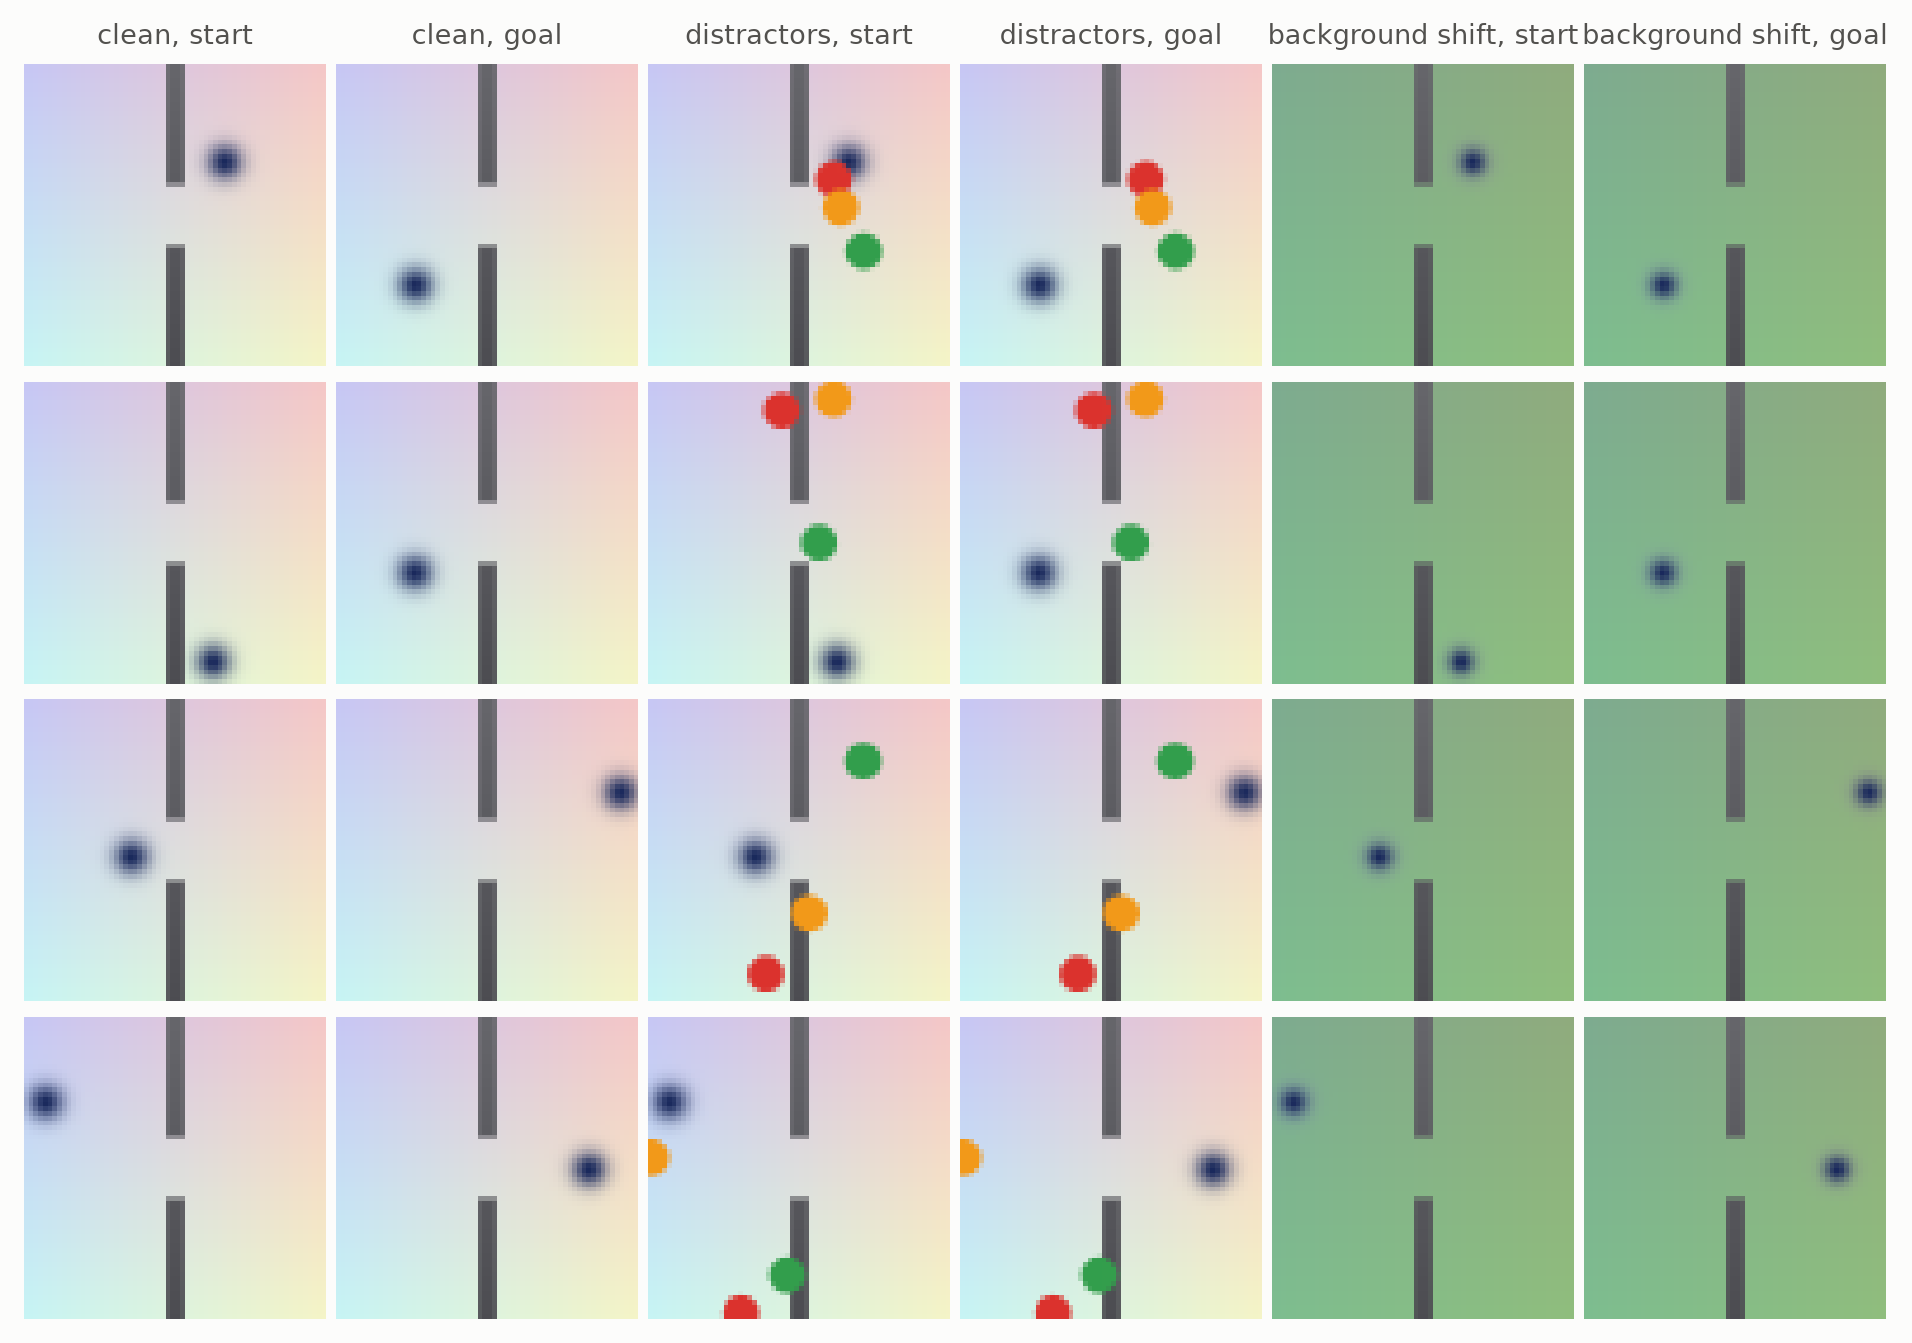

In [3]:
conditions = {"clean": {}, "distractors": dict(distractors=3), "background shift": dict(floor=(0.3, 0.6, 0.3))}
gen = torch.Generator().manual_seed(1)
start, goal = TwoRooms(batch_size=4).tasks(gen)
frames = []
for kwargs in conditions.values():
    env = TwoRooms(batch_size=4, **kwargs)
    env.reset(start, generator=torch.Generator().manual_seed(2))
    frames += [env.render(start), env.render(goal)]
frames = torch.stack(frames, 1).flatten(0, 1)  # (4 tasks x 6 panels, 3, 64, 64)
titles = [f"{c}, {w}" for c in conditions for w in ("start", "goal")] + [""] * 18
plots.images(frames, titles=titles, ncols=6, size=1.3)

## Data
As in the main benchmark: 1024 clean episodes of 65 steps of a point that keeps its previous action 80% of the time.

In [4]:
data = TwoRooms(batch_size=1024, device=device).collect(65, generator=torch.Generator().manual_seed(0))


def loader(window):
    return DataLoader(TrajectoryDataset(data, window=window), batch_size=128, shuffle=True, drop_last=True)

## Models and training
The main benchmark's models and recipes, unchanged: 5 epochs each on clean data.

/clusterhome/kleyton/pytorch-world-p2-20261025/pydeps/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


LeWM           2.6 min


PLDM           8.1 min


DINO-WM        2.8 min


/clusterhome/kleyton/.local/share/uv/python/cpython-3.12.13-linux-aarch64-gnu/lib/python3.12/contextlib.py:105: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)


V-JEPA 2-AC   10.3 min


TD-MPC2        0.9 min


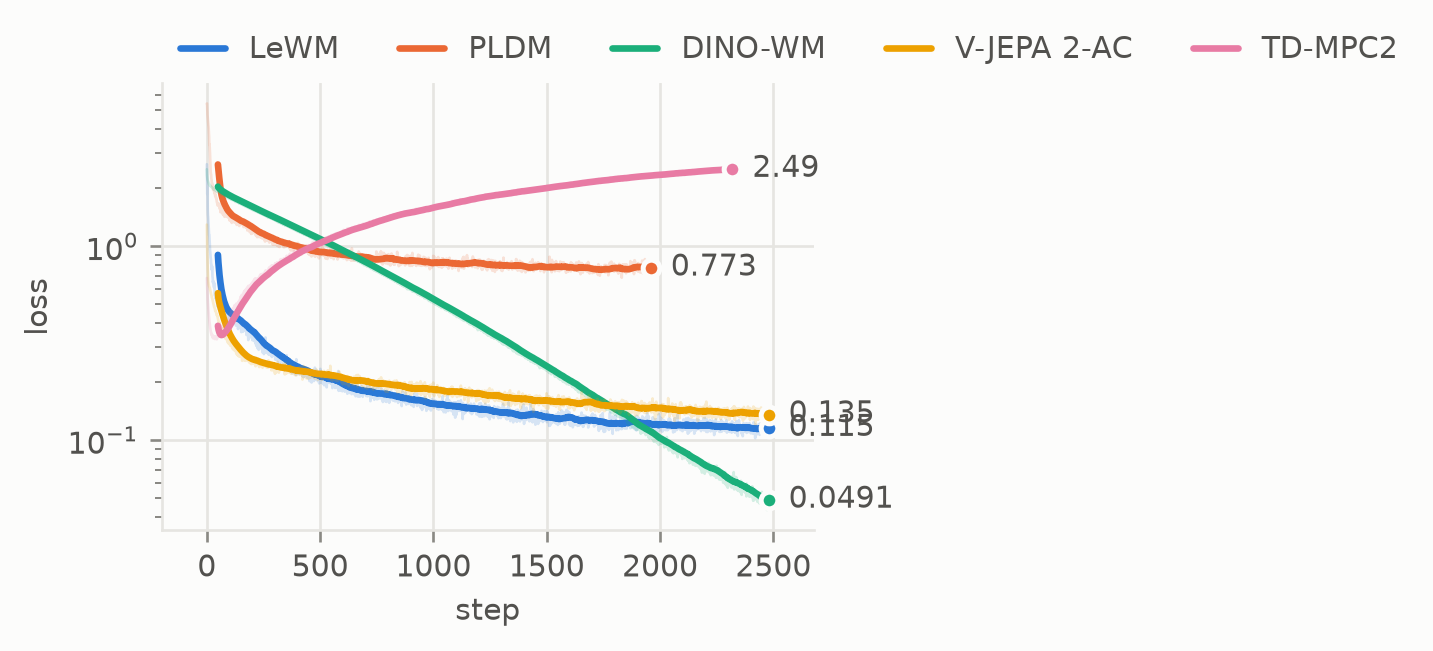

In [5]:
predictor = dict(depth=4, num_heads=4, head_dim=32, mlp_dim=512)
models = {
    "LeWM": LeWM(CLSEncoder(img_size=64, patch_size=8, embed_dim=128, depth=4, num_heads=4), action_dim=2, embed_dim=128, proj_dim=512, lamb=0.05, **predictor),
    "PLDM": PLDM(PLDMEncoder(img_size=64, latent_dim=128), action_dim=2, latent_dim=128),
    "DINO-WM": DINOWM(PatchTokens.from_hub("dinov2_vits14", size=56), num_patches=16, embed_dim=384, action_dim=2, **predictor),
    "V-JEPA 2-AC": RoboJEPA(embed_dim=768, action_dim=2, encoder=VideoTokens.from_hub("vjepa2_1_vit_base_384", size=64), predictor_dim=256, depth=4, num_heads=4),
    "TD-MPC2": TDMPC2(pixel_encoder(in_channels=6), action_dim=2, latent_dim=512, mlp_dim=512, discount=TDMPC2.episode_discount(60)),
}
v_jepa, tdmpc2 = models["V-JEPA 2-AC"], models["TD-MPC2"]


def hindsight(batch):
    pixels, states = batch["pixels"], batch["states"]  # (B, 8, ...)
    B = len(pixels)
    same = torch.rand(B, device=device) < 0.5
    other = torch.where(same, torch.arange(B, device=device), torch.randperm(B, device=device))
    goal_pixels, goal_states = pixels[other, -1], states[other, -1]
    obs = torch.cat([pixels[:, :4], goal_pixels[:, None].expand(-1, 4, -1, -1, -1)], dim=2)
    rewards = -(states[:, 1:4] - goal_states[:, None]).norm(dim=-1)
    return obs, batch["actions"][:, :3], rewards


recipes = {
    "LeWM": dict(window=4),
    "PLDM": dict(window=17, lr=1e-3, weight_decay=0),
    "DINO-WM": dict(window=4),
    "V-JEPA 2-AC": dict(window=4, inputs=lambda b: (v_jepa.encode(b["pixels"]), b["actions"])),
    "TD-MPC2": dict(window=8, inputs=hindsight, lr=3e-4, clip=20, step=tdmpc2.update_target),
}
logs, minutes = {}, {}
for name, model in models.items():
    recipe = dict(recipes[name])
    tic = time.time()
    logs[name] = fit(model.to(device), loader(recipe.pop("window")), epochs=5, **recipe)["loss"]
    minutes[name] = (time.time() - tic) / 60
    print(f"{name:12s} {minutes[name]:5.1f} min")
plots.curves(logs, smooth=50)

## How far a nuisance moves each latent
Before planning: how far does each encoder move a frame's latent when the discs or the tint are added, compared with moving the point by 0.1, the success radius? Distances use each model's own planning cost, over 256 random states. A ratio above 1 means that, to the planner's cost, the nuisance looks farther than a goal-sized step. TD-MPC2 encodes the frame and the goal together and plans on values, not latent distances, so it is left out.

In [6]:
@torch.no_grad()
def latents(model, images):
    return torch.cat([model.encode(x[:, None].to(device))[:, 0] for x in images.split(64)])


probe = TwoRooms(batch_size=256)
states = probe.free(256, generator=torch.Generator().manual_seed(3))
angle = torch.rand(256, generator=torch.Generator().manual_seed(4)) * 2 * torch.pi
moved = (states + 0.1 * torch.stack([angle.cos(), angle.sin()], -1)).clamp(probe.low, probe.high)
images = {"0.1 step": probe.render(moved)}
for condition, kwargs in list(conditions.items())[1:]:
    env = TwoRooms(batch_size=256, **kwargs)
    env.reset(states, generator=torch.Generator().manual_seed(5))
    images[condition] = env.render(states)

sensitivity = {}
for name in ["LeWM", "PLDM", "DINO-WM", "V-JEPA 2-AC"]:
    model = models[name]
    clean = latents(model, probe.render(states))
    cost = {k: model.cost(latents(model, x)[:, None], clean).mean().item() for k, x in images.items()}
    sensitivity[name] = {k: cost[k] / cost["0.1 step"] for k in conditions if k != "clean"}
    print(f"{name:12s} " + "  ".join(f"{k}: {v:5.2f}x a 0.1 step" for k, v in sensitivity[name].items()))

LeWM         distractors:  1.08x a 0.1 step  background shift: 15.12x a 0.1 step
PLDM         distractors:  0.36x a 0.1 step  background shift:  0.01x a 0.1 step
DINO-WM      distractors:  4.04x a 0.1 step  background shift:  4.61x a 0.1 step


/clusterhome/kleyton/.local/share/uv/python/cpython-3.12.13-linux-aarch64-gnu/lib/python3.12/contextlib.py:105: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)


V-JEPA 2-AC  distractors:  1.30x a 0.1 step  background shift:  1.34x a 0.1 step


## Evaluate
The main benchmark's protocol and planners: 60 steps, success when the point comes within 0.1 of the goal at any step, 95% Wilson intervals. The same starts and goals are used under every condition, so the conditions differ only in the images.

One change saves time without changing any success: an episode that has reached its goal stops (its agent stays put), and the planner only runs for the others. Success is already decided at that point, but final distance and smoothness are not those of the main benchmark, and the wall time per step is not comparable. The frozen-encoder planners still cost about 17 s (DINO-WM) and 42 s (V-JEPA 2-AC) per step for 32 episodes on a GB10, so this notebook uses **24 tasks of each kind** per condition, which keeps it within about 3–4 hours on one GB10 shared with other jobs (a failed episode plans all 60 steps). This run took 1 h 42 min in all: 25 minutes of training and 77 of planning.

In [7]:
cem = CEM(horizon=8, action_dim=2, num_samples=128, num_elites=16, iterations=5, bounds=(-1, 1), objective="path")
mppi = MPPI(horizon=3, action_dim=2, num_samples=256, num_elites=32, num_pi_trajs=12, iterations=4)
num_tasks = 24


def stopping(env, goal, plan):
    # Plans with plan(obs, todo) -> (len(todo), 2) for the episodes that have not reached the goal; the others stay put.
    done, calls = torch.zeros(env.batch_size, dtype=torch.bool, device=device), [0]

    def policy(obs):
        if calls[0]:
            done.logical_or_(env.success(env.state, goal))
        calls[0] += 1
        action, todo = torch.zeros(len(obs), 2, device=obs.device), (~done).nonzero().squeeze(1)
        if len(todo):
            action[todo] = plan(obs, todo).to(action)
        return action

    return policy


def policies(env, goal, goal_images):
    def latent_planner(model):
        goal_z = latents(model, goal_images)
        return lambda obs, todo: cem(model, model.encode(obs[todo, None]), goal_z[todo])[:, 0]

    plans = {name: latent_planner(models[name]) for name in ["LeWM", "PLDM", "DINO-WM", "V-JEPA 2-AC"]}
    mppi.reset()  # TD-MPC2's MPPI warm-starts from its last plan, so it plans for the whole batch
    plans["TD-MPC2"] = lambda obs, todo: mppi(tdmpc2, tdmpc2.encode(torch.cat([obs, goal_images], dim=1)[:, None]))[todo, 0]
    seeded = torch.Generator(device).manual_seed(4)  # the same random actions under every condition
    plans["random actions"] = lambda obs, todo: (torch.rand(len(obs), 2, generator=seeded, device=device) * 2 - 1)[todo]
    return {name: stopping(env, goal, plan) for name, plan in plans.items()}


results = {}
for task, same_room in [("same room", True), ("other room", False)]:
    start, goal = TwoRooms(batch_size=num_tasks).tasks(torch.Generator().manual_seed(1), same_room=same_room)
    start, goal = start.to(device), goal.to(device)
    for condition, kwargs in conditions.items():
        tic = time.time()
        env = TwoRooms(batch_size=num_tasks, device=device, **kwargs)
        env.reset(goal, generator=torch.Generator().manual_seed(2))  # places the discs drawn in the goal images
        goal_images = env.render(goal)
        torch.manual_seed(3)  # the discs' starts and drift during the episodes
        results[task, condition] = evaluation.goal_reaching(env, policies(env, goal, goal_images), start, goal, steps=60, success="reached")
        print(f"== {task}, {condition} ({(time.time() - tic) / 60:.0f} min)\n{results[task, condition]}")

== same room, clean (5 min)
                          success  reached   steps  final distance  progress     SPL  smoothness  ms / step
LeWM               62% [43%, 79%]      62%    2.27          0.0756     0.658   0.624       0.144        132
PLDM             100% [86%, 100%]     100%    3.46          0.0583     0.785   0.993      0.0298      0.803
DINO-WM            88% [69%, 96%]      88%    3.05          0.0682     0.751   0.869      0.0482        931
V-JEPA 2-AC        83% [64%, 93%]      83%     4.6          0.0542     0.801   0.794      0.0899   3.88e+03
TD-MPC2              4% [1%, 20%]       8%     3.5           0.479    -0.368  0.0408        0.01       6.69
random actions     62% [43%, 79%]      62%    23.2          0.0878     0.457   0.321       0.652     0.0798


== same room, distractors (8 min)
                          success  reached   steps  final distance  progress     SPL  smoothness  ms / step
LeWM               79% [60%, 91%]      79%    10.8          0.0759      0.74   0.652       0.259        117
PLDM             100% [86%, 100%]     100%    3.88          0.0597     0.827   0.984       0.032      0.743
DINO-WM            83% [64%, 93%]      83%    12.4          0.0827     0.749   0.593       0.195   1.87e+03
V-JEPA 2-AC        75% [55%, 88%]      75%    7.44           0.079     0.709   0.571       0.291   5.78e+03
TD-MPC2              4% [1%, 20%]       8%     3.5           0.479    -0.368  0.0411     0.00959       5.79
random actions     62% [43%, 79%]      62%    23.2          0.0878     0.457   0.321       0.652     0.0823


== same room, background shift (11 min)
                          success  reached   steps  final distance  progress     SPL  smoothness  ms / step
LeWM               46% [28%, 65%]      46%    14.3           0.171     0.246   0.384       0.215        208
PLDM             100% [86%, 100%]     100%    3.46          0.0605     0.782   0.992      0.0289       0.65
DINO-WM            62% [43%, 79%]      62%    11.6          0.0975     0.549   0.477       0.198   2.73e+03
V-JEPA 2-AC        54% [35%, 72%]      58%       3          0.0939     0.562   0.518       0.262   8.22e+03
TD-MPC2              4% [1%, 20%]       8%     3.5           0.479    -0.368   0.041      0.0091       5.92
random actions     62% [43%, 79%]      62%    23.2          0.0878     0.457   0.321       0.652     0.0801


== other room, clean (17 min)
                          success  reached   steps  final distance  progress     SPL  smoothness  ms / step
LeWM               29% [15%, 49%]      29%    7.57           0.489     0.272   0.266       0.197        236
PLDM               75% [55%, 88%]      75%    6.44          0.0603     0.861   0.664       0.131        3.4
DINO-WM            29% [15%, 49%]      29%    6.43           0.439     0.185   0.276       0.258   4.08e+03
V-JEPA 2-AC        29% [15%, 49%]      29%    5.57           0.324     0.237   0.264       0.329   1.23e+04
TD-MPC2              0% [0%, 14%]       0%     nan           0.665    -0.163       0     0.00815       5.89
random actions       0% [0%, 14%]       0%     nan            0.62   -0.0227       0        1.05      0.081


== other room, distractors (18 min)
                          success  reached   steps  final distance  progress     SPL  smoothness  ms / step
LeWM               29% [15%, 49%]      29%    22.1           0.535    -0.108   0.154       0.579        260
PLDM               75% [55%, 88%]      75%    11.9          0.0887     0.825   0.577       0.187       3.91
DINO-WM             21% [9%, 40%]      21%    17.8           0.545    0.0532   0.133       0.579    4.7e+03
V-JEPA 2-AC        33% [18%, 53%]      33%    24.5           0.261     0.268   0.213         0.6   1.34e+04
TD-MPC2              0% [0%, 14%]       0%     nan           0.665    -0.163       0     0.00862       5.74
random actions       0% [0%, 14%]       0%     nan            0.62   -0.0227       0        1.05     0.0824


== other room, background shift (18 min)
                          success  reached   steps  final distance  progress     SPL  smoothness  ms / step
LeWM                 0% [0%, 14%]       0%     nan           0.584   0.00233       0       0.325        323
PLDM               79% [60%, 91%]      79%    6.79          0.0665      0.88   0.697       0.122       3.37
DINO-WM            29% [15%, 49%]      29%    19.1           0.229     0.351   0.212       0.348   4.41e+03
V-JEPA 2-AC        29% [15%, 49%]      29%    15.9           0.188     0.406   0.236       0.316   1.32e+04
TD-MPC2              0% [0%, 14%]       0%     nan           0.665    -0.163       0     0.00802       5.97
random actions       0% [0%, 14%]       0%     nan            0.62   -0.0227       0        1.05     0.0824


## Results
Success under each condition, per kind of task. The gray bar is random actions, which never look at the images: they draw the same actions under every condition, so their success cannot change and they show that the tasks themselves are the same.

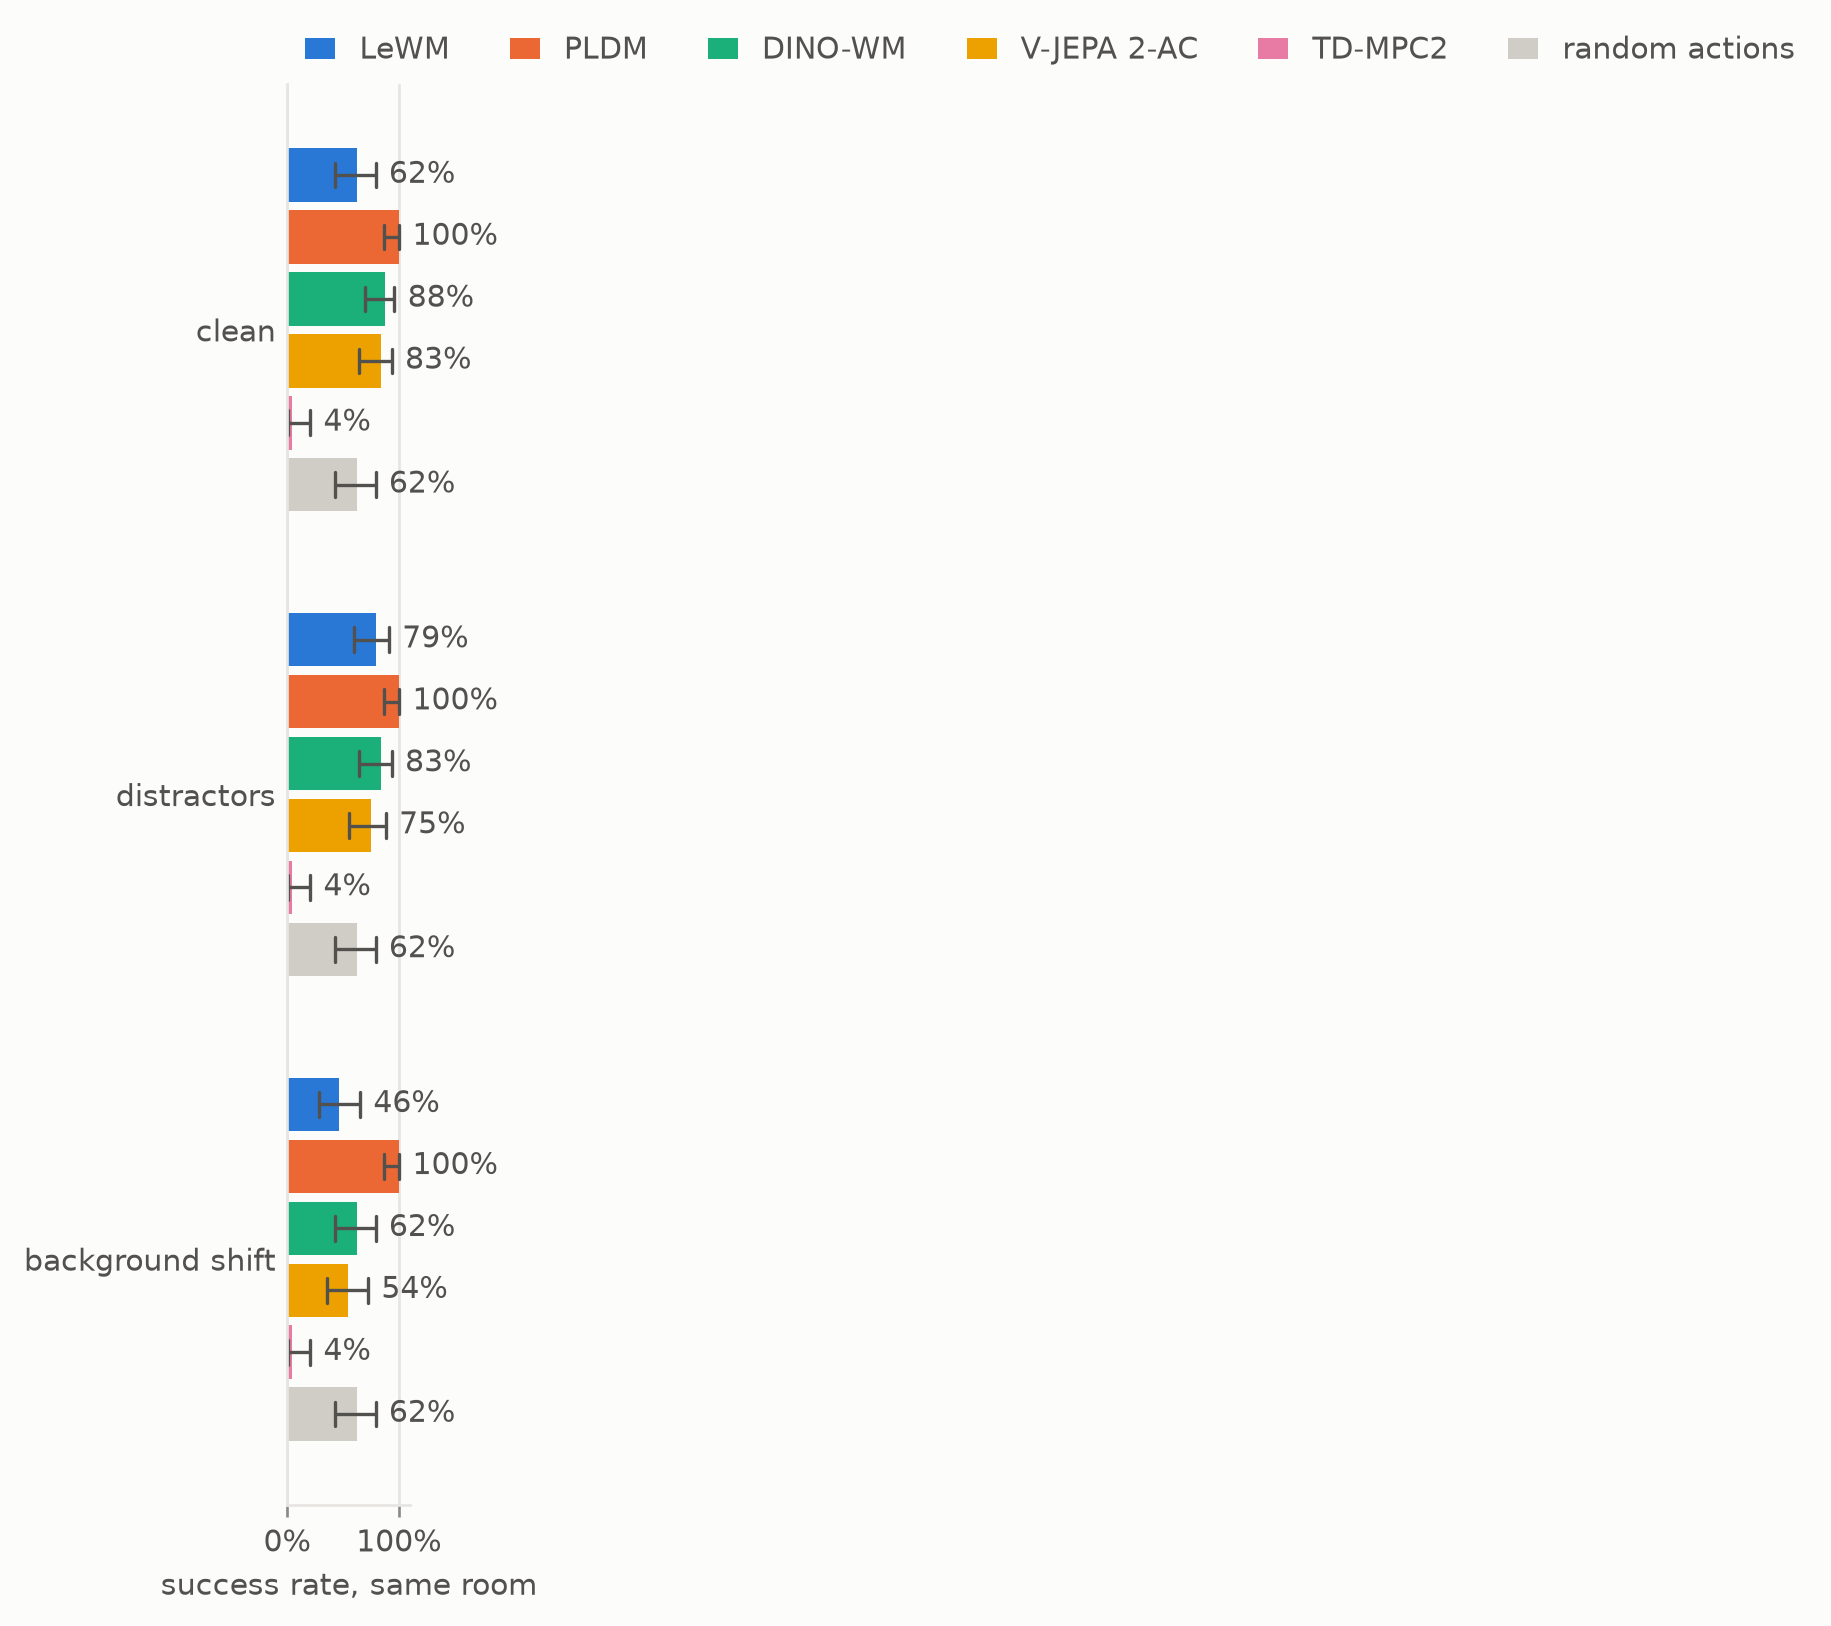

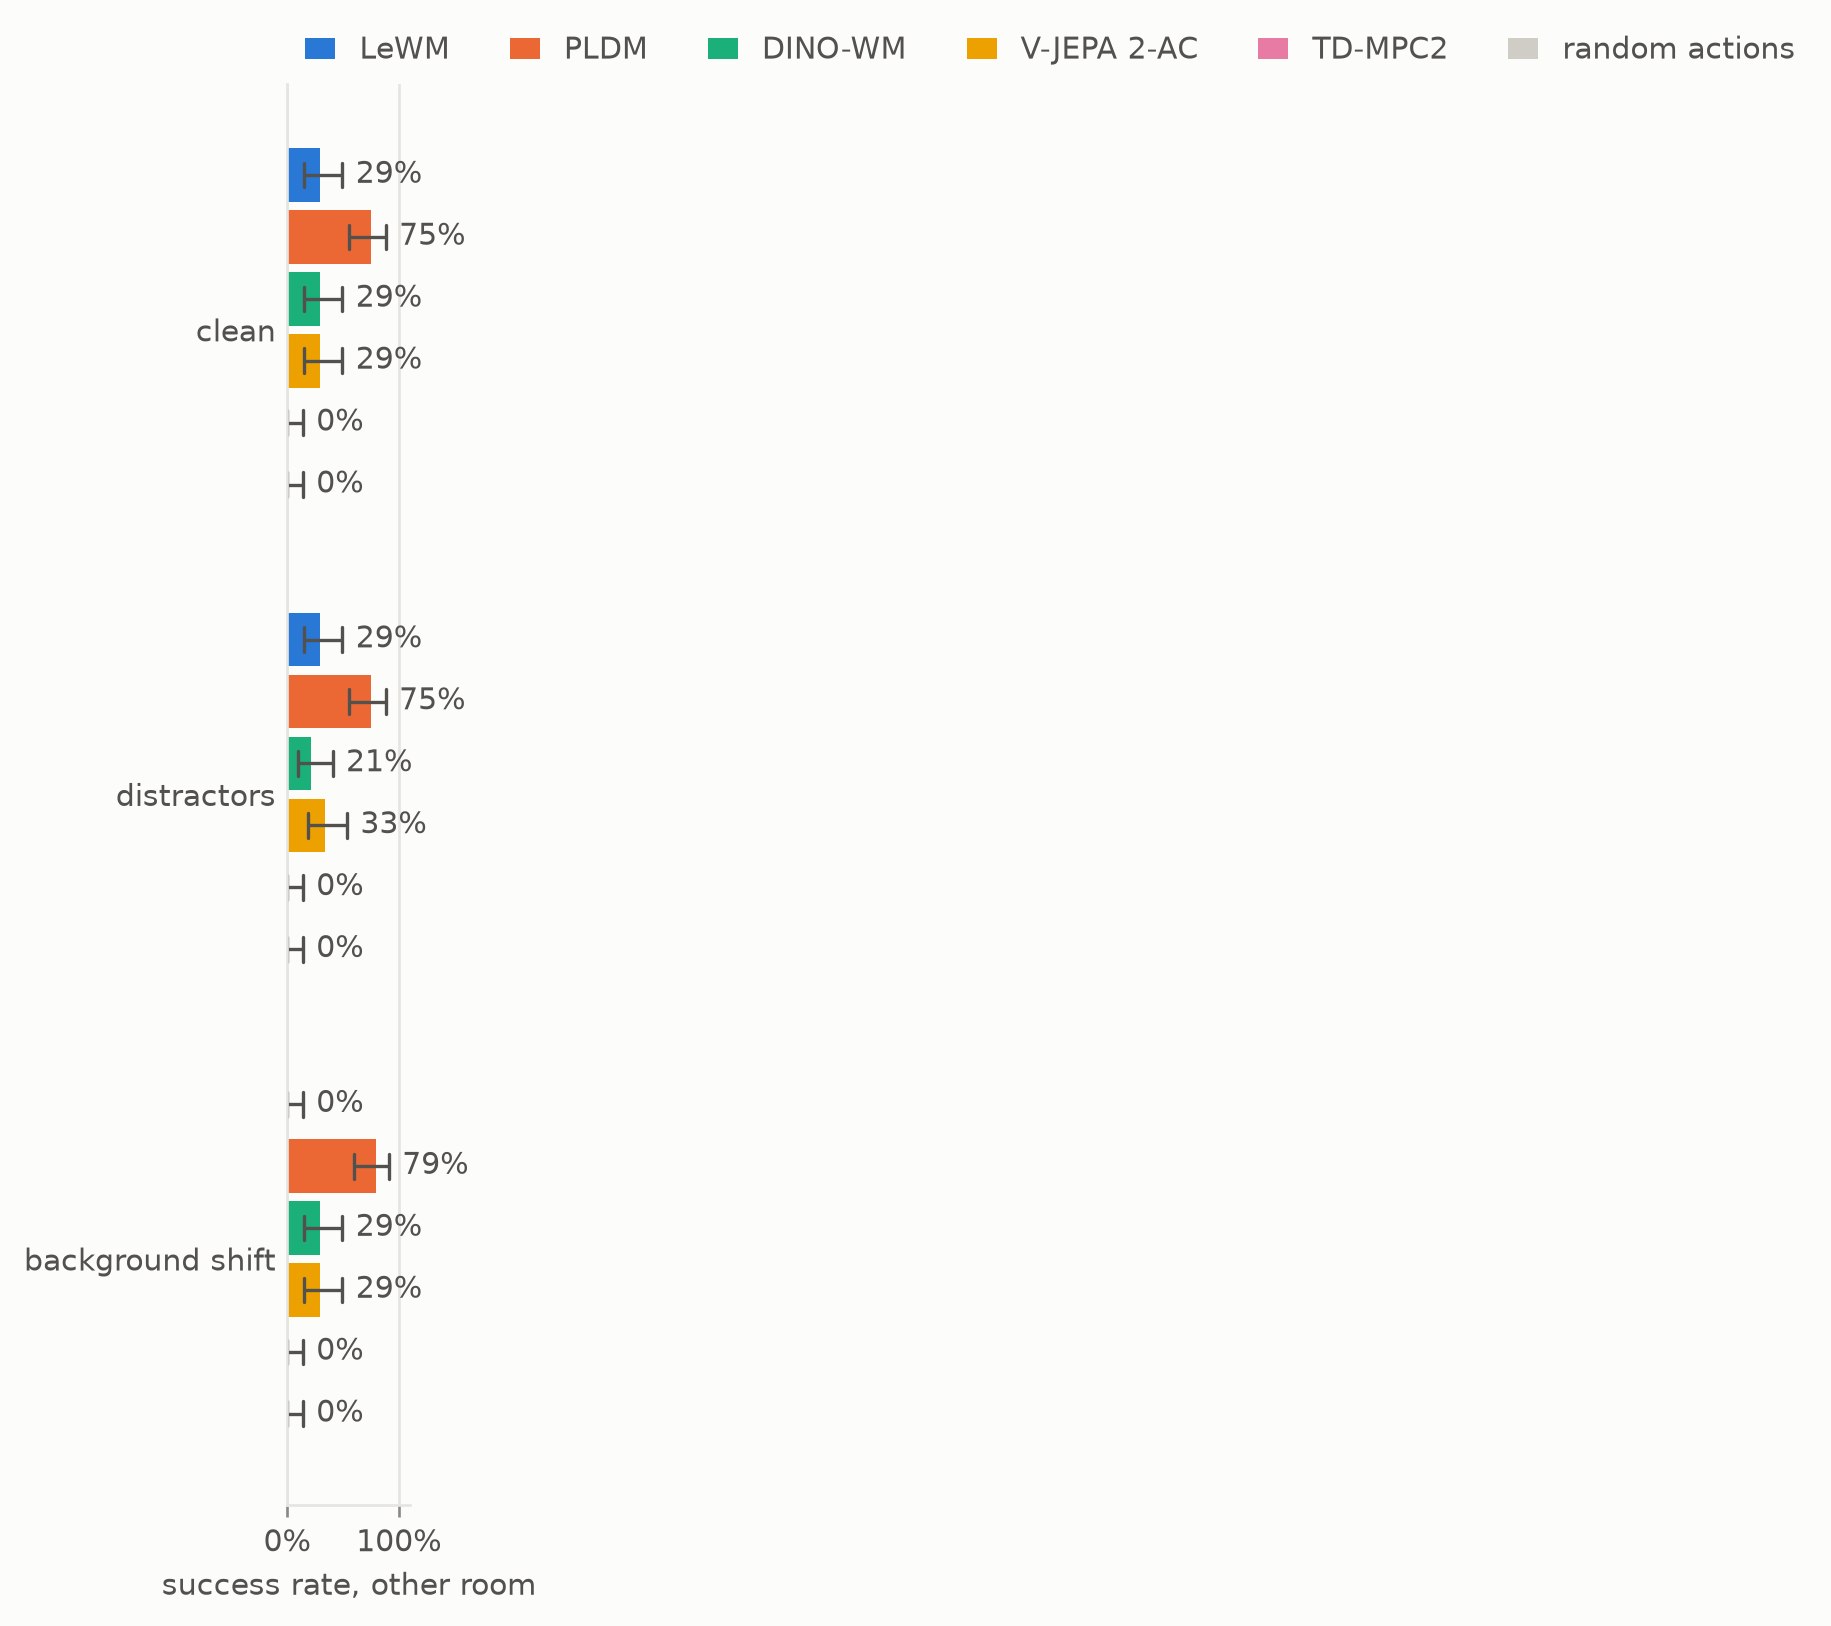

In [8]:
for task in ["same room", "other room"]:
    display(plots.bars({c: results[task, c].intervals() for c in conditions}, xlabel=f"success rate, {task}", baseline="random actions"))

The relative drop is how much of its clean success a model loses: 1 − success under the nuisance / clean success (negative when it does better). With 24 tasks the intervals are wide, so only large drops are clear.

In [9]:
names = list(models) + ["random actions"]
for task in ["same room", "other room"]:
    rates = {c: results[task, c].intervals() for c in conditions}
    print(f"== {task}\n{'':16s}" + "".join(f"{c:>20s}" for c in conditions) + f"{'drop, distractors':>19s}{'drop, background':>18s}")
    for name in names:
        clean = rates["clean"][name].value
        drops = [f"{1 - rates[c][name].value / clean:+.0%}" if clean else "n/a" for c in list(conditions)[1:]]
        print(f"{name:16s}" + "".join(f"{rates[c][name]!s:>20}" for c in conditions) + f"{drops[0]:>19s}{drops[1]:>18s}")

== same room
                               clean         distractors    background shift  drop, distractors  drop, background
LeWM                  62% [43%, 79%]      79% [60%, 91%]      46% [28%, 65%]               -27%              +27%
PLDM                100% [86%, 100%]    100% [86%, 100%]    100% [86%, 100%]                +0%               +0%
DINO-WM               88% [69%, 96%]      83% [64%, 93%]      62% [43%, 79%]                +5%              +29%
V-JEPA 2-AC           83% [64%, 93%]      75% [55%, 88%]      54% [35%, 72%]               +10%              +35%
TD-MPC2                 4% [1%, 20%]        4% [1%, 20%]        4% [1%, 20%]                +0%               +0%
random actions        62% [43%, 79%]      62% [43%, 79%]      62% [43%, 79%]                +0%               +0%
== other room
                               clean         distractors    background shift  drop, distractors  drop, background
LeWM                  29% [15%, 49%]      29% [15%, 49%]     

## Summary
Over 24 tasks of each kind, PLDM is the only model the nuisances do not touch: 100% in the same room and 75–79% through the door under every condition. Its encoder hardly moves when discs or a tint are added (0.36 and 0.01 times a 0.1 step), so its planning cost does not see them.

The background shift is the harder nuisance for the others. In the same room DINO-WM falls from 88% to 62%, V-JEPA 2-AC from 83% to 54% and LeWM from 62% to 46%; through the door LeWM falls from 29% to 0%, the one drop whose intervals do not overlap, in line with its latent moving 15 times a goal-sized step under the tint. The frozen web encoders move less (4.6 and 1.3 times) and keep their 29% through the door.

Distractors cost less than one would expect: no success rate changes by more than the intervals, although the agents that plan on the frozen encoders and on LeWM take several times more steps to reach a goal (DINO-WM from 3 to 12 in the same room). DINO-WM's patch features move the most under the discs (4 times a 0.1 step), but three small discs touch few of its 16 patches and its cost averages over them.

TD-MPC2's success is the same under every condition only because it reaches almost no goal at all (its actions hardly change, smoothness 0.01), so it says nothing about robustness. Random actions are identical under every condition by construction, so the tasks are the same. LeWM's clean same-room success (62%) is below the main benchmark's (78%) with the same recipe: run-to-run variance at this scale is of the order of the intervals, about ±20 points with 24 tasks, so only large drops are clear here.